# 2. Injection des attaques de transmission (MITM et injection)

**Objectif.** Fabriquer le jeu de données d'étude : les traces réelles, dans lesquelles un attaquant
modifie les mesures **pendant leur trajet** entre le capteur et le broker MQTT. Le capteur fonctionne,
mais le serveur reçoit une fausse valeur.

| Scénario | Capteur visé | Ce que fait l'attaquant |
| --- | --- | --- |
| `MITM_gel` | frigo | répète la dernière valeur en boucle |
| `MITM_rejeu` | frigo | renvoie une fenêtre passée (au moins 1 h plus tôt) |
| `Injection_nominale` | frigo | envoie des valeurs forgées autour de 7 °C, peu bruitées |
| `Injection_biais_0.5` / `_1.0` / `_2.0` | frigo | décale toutes les mesures de −0,5 / −1 / −2 °C |
| `Injection_derive` | frigo | décale peu à peu, de 0 à −2 °C |
| `MITM_gel_thermostat` | salle | répète la dernière valeur |
| `Injection_biais_thermostat` | salle | décale de −1,5 °C |

Le « masquage » (cacher une vraie hausse) est abandonné : ces traces n'ont pas d'excursion réelle à cacher.

In [1]:
%%capture
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())
sys.path[:0] = [str(ROOT / "backend"), str(ROOT / "backend" / "scripts")]
import build_dataset as bd
import transmission_real as tr
import transmission_models as tm
import transmission_study as ts
from app.api.v1 import phase2
from app.core import paths

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 3.5)
SEED = tr.SEED
COLS = {"weather": "temperature", "fridge": "fridge_temperature", "thermostat": "current_temperature"}
EPISODES_PATH = paths.PROCESSED_DIR / "episodes_transmission_reel.json"
MODEL_DIR = paths.MODELS_DIR / "transmission_reel"

In [2]:
base = pd.read_csv(paths.PROCESSED_DIR / "traces_reelles_5s.csv", parse_dates=["datetime"])
base["fridge_cond"] = base["fridge_cond"].astype(str)
print(f"{len(base):,} lignes de traces réelles fusionnées")

44,443 lignes de traces réelles fusionnées


## 2.1 Découpage en blocs et planning des attaques

- Les 62 heures sont découpées en **blocs d'une heure**, attribués en boucle : 3 blocs d'entraînement,
  1 de validation, 1 de test.
- Un **épisode d'attaque de 12 à 20 minutes** est placé dans un bloc sur deux de chaque rôle.
  Les modèles supervisés (Random Forest, XGBoost) ont besoin d'attaques dans l'entraînement.
- Après chaque épisode, 5 minutes sont exclues de l'évaluation (les fenêtres glissantes traînent encore l'attaque).
- Les scénarios se suivent en boucle, pour que chacun apparaisse dans chaque rôle.

In [3]:
rng = np.random.default_rng(SEED)
episodes = tr.build_schedule(len(base), rng, run=0, roles=("train", "val", "test"))
plan = pd.DataFrame(episodes)
plan["début"] = base["datetime"].iloc[plan["start"]].values
plan["durée (min)"] = (plan["end"] - plan["start"]) * 5 / 60
plan[["name", "sensor", "kind", "param", "split", "début", "durée (min)"]]

,name,sensor,kind,param,split,début,durée (min)
0,MITM_gel,fridge,gel,NaN,train,2019-04-01 14:59:55,13.583333
1,MITM_rejeu,fridge,rejeu,NaN,train,2019-04-01 17:03:00,15.833333
2,MITM_gel,fridge,gel,NaN,val,2019-04-01 18:07:25,15.000000
3,MITM_gel,fridge,gel,NaN,test,2019-04-01 19:00:35,19.833333
4,Injection_nominale,fridge,nominale,NaN,train,2019-04-01 21:16:35,14.000000
5,Injection_biais_0.5,fridge,biais,-0.5,train,2019-04-02 00:55:50,15.750000
6,Injection_biais_1.0,fridge,biais,-1.0,train,2019-04-02 04:02:45,15.916667
7,MITM_rejeu,fridge,rejeu,NaN,val,2019-04-02 07:21:15,17.416667
8,MITM_rejeu,fridge,rejeu,NaN,test,2019-04-02 08:22:10,17.666667
9,Injection_biais_2.0,fridge,biais,-2.0,train,2019-04-02 10:35:10,16.500000


In [4]:
df = tr.inject(base, episodes, rng, run=0)
bilan = df.groupby("split")["label"].agg(lignes="size", attaques="sum")
bilan["part d'attaques"] = (100 * bilan["attaques"] / bilan["lignes"]).round(1).astype(str) + " %"
bilan

,lignes,attaques,part d'attaques
split,,,
test,8640,1229,14.2 %
train,27163,3796,14.0 %
val,8640,1161,13.4 %


## 2.2 À quoi ressemble chaque attaque ?

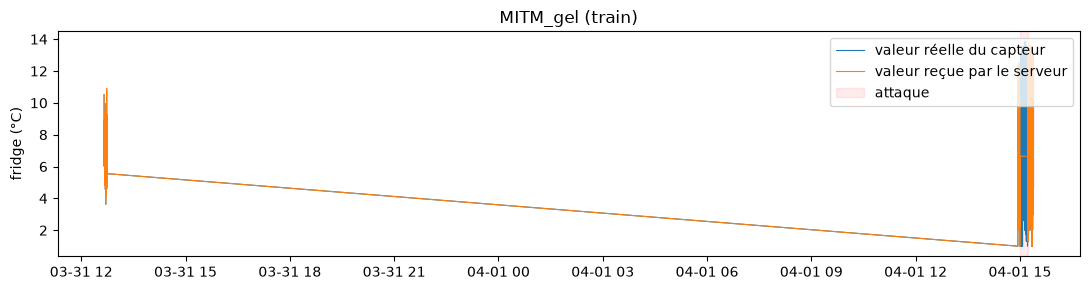

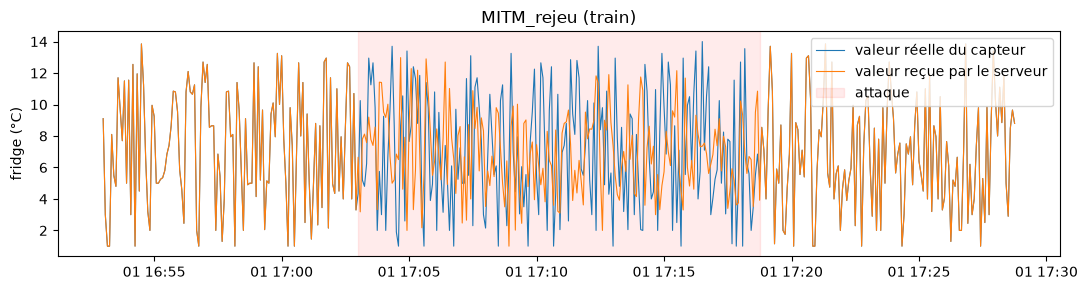

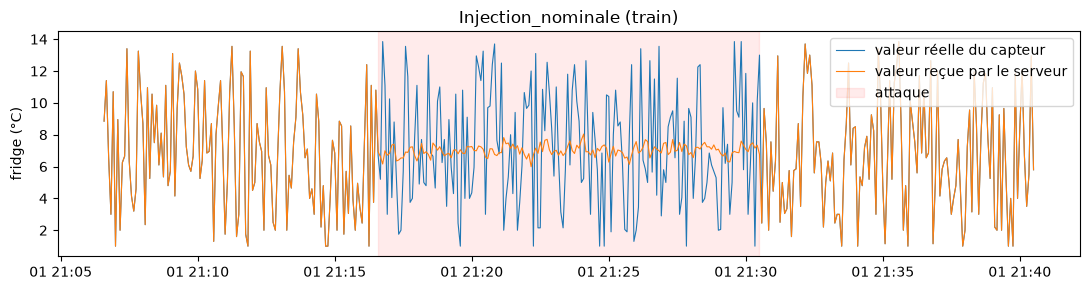

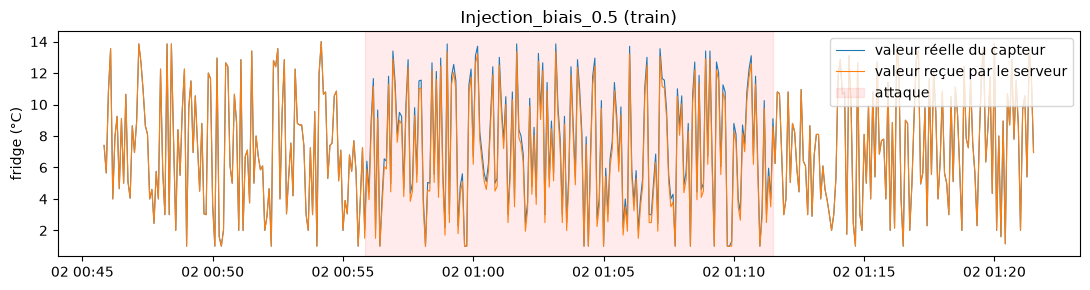

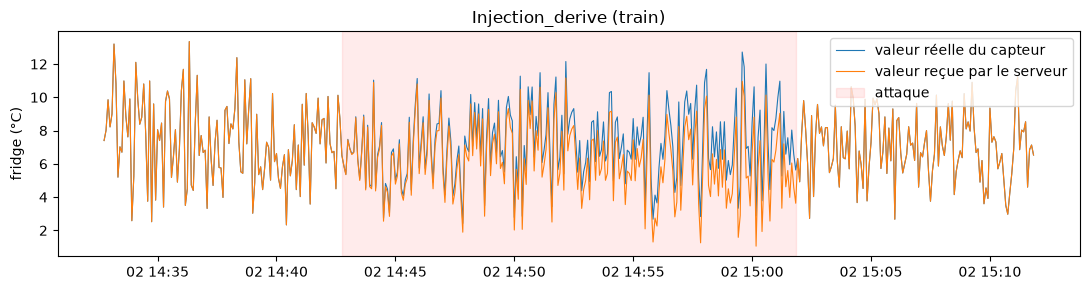

In [5]:
def montrer(kind, marge=120):
    ep = next(e for e in episodes if e["kind"] == kind)
    col = "fridge" if ep["sensor"] == "fridge" else "thermostat"
    a, b = ep["start"] - marge, ep["end"] + marge
    t = df["datetime"].iloc[a:b]
    plt.figure(figsize=(11, 3))
    plt.plot(t, df[f"{col}_true"].iloc[a:b], lw=0.8, label="valeur réelle du capteur")
    plt.plot(t, df[f"{col}_temp"].iloc[a:b], lw=0.8, label="valeur reçue par le serveur")
    plt.axvspan(df["datetime"].iloc[ep["start"]], df["datetime"].iloc[ep["end"] - 1], color="red", alpha=0.08, label="attaque")
    plt.title(f"{ep['name']} ({ep['split']})"); plt.ylabel(f"{col} (°C)"); plt.legend(loc="upper right"); plt.tight_layout()

for kind in ("gel", "rejeu", "nominale", "biais", "derive"):
    montrer(kind)

Le gel et l'injection nominale se voient à l'œil : la mesure ne bouge plus, ou devient trop
régulière. Le rejeu et les biais sont invisibles à l'œil : les valeurs rejouées ou décalées ont
la même allure que les vraies. Seul un calcul (niveau moyen, séquence déjà vue) peut les repérer.

## 2.3 Features et enregistrement du jeu de données

In [6]:
df, feats = tm.engineer(df)
df.to_csv(tr.DATASET_PATH, index=False, float_format="%.4f")
with open(EPISODES_PATH, "w", encoding="utf-8") as f:
    json.dump(episodes, f, indent=1)
print("Jeu de données :", tr.DATASET_PATH, f"({len(df):,} lignes, {len(feats)} features)")
print("Planning des attaques :", EPISODES_PATH, f"({len(episodes)} épisodes)")

Jeu de données : /home/bilel/Desktop/surveillance-produits-pharmaceutiques/data/processed/dataset_transmission_reel.csv (44,443 lignes, 35 features)
Planning des attaques : /home/bilel/Desktop/surveillance-produits-pharmaceutiques/data/processed/episodes_transmission_reel.json (31 épisodes)


Ce fichier correspond à la **répétition 0** de l'étude. Comme les traces ne durent que 62 heures,
le script `backend/scripts/transmission_models.py` rejoue 9 fois ce découpage en faisant tourner les
rôles des heures et les scénarios, puis cumule les résultats. Les notebooks suivants travaillent sur
la répétition 0 et affichent aussi le résultat cumulé.